# Đường cong học: học có giám sát (SL) và học tăng cường tự chơi (RL)

Notebook này đọc các file log do nhóm tạo ra và vẽ lại đường cong học của cấp 5 (SL) và cấp 6 (RL). Không có số liệu nào nhập tay.

| File | Do lệnh nào tạo |
|---|---|
| `logs/training/sl_log.csv` | `python -m training.train_sl ...` |
| `logs/training/rl_log.csv` | `python -m training.train_rl --iterations 300 --games 32 --save-every 50 --seed 0 ...` |
| `logs/training/rl_curve.csv` | `python training/eval_anchors.py --ckpt ... --label ... --out logs/training/rl_curve.csv` |

Chạy từ đầu đến cuối bằng **Run All**. Hình ra file `results/figures/fig_learning_curve.png`.

In [4]:
import os, sys
# Notebook nằm trong notebooks/, đưa thư mục làm việc về gốc repo để đường dẫn khớp lệnh trong README
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT)
sys.path.insert(0, ROOT)

import csv
from IPython.display import Image, display
from training import plot_rl_curves as prc

print("Thư mục gốc repo:", ROOT)

Thư mục gốc repo: /home/hbup/TTNTNC-GameAI-nhom11


## 1. Học có giám sát (cấp 5)
Đường cong học của `train_sl.py` (5000 ván của giáo viên Think3; checkpoint chọn theo loss val thấp nhất, epoch 4). Hình do `training/plot_curves.py` vẽ.

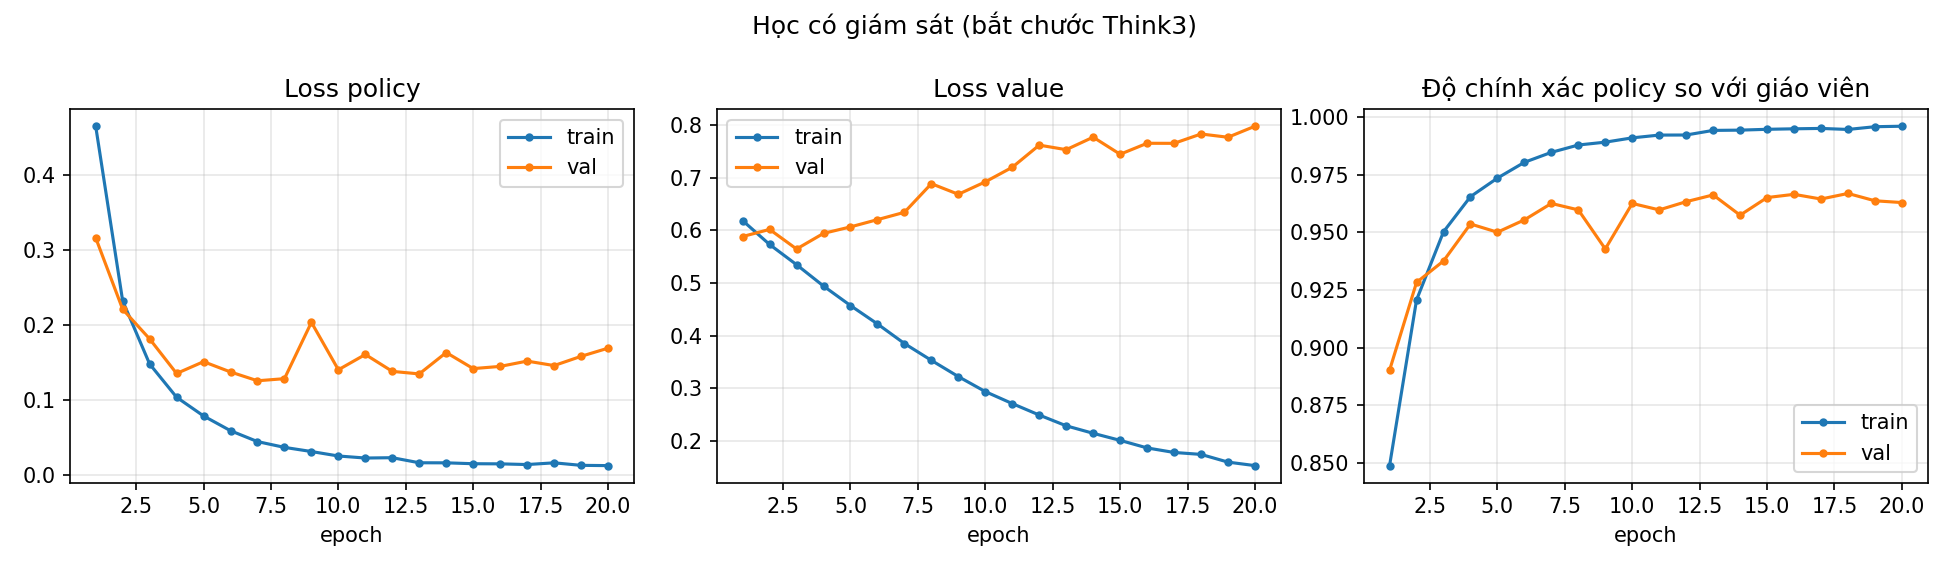

In [5]:
display(Image("docs/images/sl_curves.png"))

## 2. Học tăng cường tự chơi (cấp 6): kết quả tự chơi
Mỗi vòng mạng tự chơi 32 ván với chính nó. Bảng dưới là trung bình theo từng khối 50 vòng (tính từ `rl_log.csv`).

In [6]:
sp = prc.load_selfplay("logs/training/rl_log.csv")
n = len(sp["iter"])
print(f"{n} vòng, {sp['games'][0]} ván mỗi vòng")
print(f"{'vòng':>9} {'đỏ thắng':>9} {'vàng thắng':>11} {'hòa':>6} {'số nước/ván':>12}")
for a in range(0, n, 50):
    b = slice(a, min(a + 50, n))
    avg = lambda k: sum(sp[k][b]) / len(sp[k][b])
    print(f"{a+1:>4}-{min(a+50, n):<4} {avg('red'):>9.1f} {avg('yellow'):>11.1f} {avg('draw'):>6.1f} {avg('moves'):>12.1f}")

300 vòng, 32 ván mỗi vòng
     vòng  đỏ thắng  vàng thắng    hòa  số nước/ván
   1-50        31.3         0.1    0.5         15.6
  51-100        7.9         5.6   18.6         37.9
 101-150       18.0         5.2    8.8         29.9
 151-200       11.5         7.3   13.2         34.7
 201-250        4.8         3.8   23.5         38.6
 251-300        1.0         1.3   29.8         41.3


## 3. Sức mạnh theo số vòng huấn luyện (đối thủ mốc)
Mỗi mốc được đo bằng `training/eval_anchors.py`: 100 ván với mỗi đối thủ (Random, Think1, Think2, Think3), đổi bên, 2 nước khai cuộc ngẫu nhiên, khoảng tin cậy Wilson 95%. Vòng 0 là bản SL (điểm xuất phát của RL).

In [7]:
an = prc.load_anchors("logs/training/rl_curve.csv")
print(f"{'vòng':>6} " + " ".join(f"{a:>22}" for a in prc.ANCHORS))
for i in range(len(an["Random"])):
    row = [f"{an[a][i][1]:.3f} [{an[a][i][2]:.2f},{an[a][i][3]:.2f}]" for a in prc.ANCHORS]
    print(f"{an['Random'][i][0]:>6} " + " ".join(f"{r:>22}" for r in row))
errors = sum(p[4] for pts in an.values() for p in pts)
print("Tổng số ván lỗi:", errors, "(phải bằng 0 thì số liệu mới dùng được)")

  vòng                 Random                 Think1                 Think2                 Think3
     0      0.910 [0.84,0.95]      0.840 [0.76,0.90]      0.275 [0.20,0.37]      0.460 [0.37,0.56]
    50      0.970 [0.92,0.99]      0.830 [0.74,0.89]      0.620 [0.52,0.71]      0.440 [0.35,0.54]
   100      0.940 [0.88,0.97]      0.830 [0.74,0.89]      0.535 [0.44,0.63]      0.555 [0.46,0.65]
   150      0.940 [0.88,0.97]      0.810 [0.72,0.88]      0.495 [0.40,0.59]      0.535 [0.44,0.63]
   200      0.960 [0.90,0.98]      0.840 [0.76,0.90]      0.500 [0.40,0.60]      0.555 [0.46,0.65]
   250      0.980 [0.93,0.99]      0.860 [0.78,0.92]      0.520 [0.42,0.61]      0.540 [0.44,0.63]
   300      0.970 [0.92,0.99]      0.850 [0.77,0.91]      0.480 [0.39,0.58]      0.545 [0.45,0.64]
Tổng số ván lỗi: 0 (phải bằng 0 thì số liệu mới dùng được)


## 4. Hình tổng hợp

In [8]:
fig = prc.draw(sp, an)
os.makedirs("results/figures", exist_ok=True)
fig.savefig("results/figures/fig_learning_curve.png", dpi=150)
fig

<Figure size 1500x420 with 3 Axes>

## 5. Nhận xét và giới hạn

- **Tự chơi chuyển pha.** Khoảng 50 vòng đầu, bên đi trước (đỏ) thắng gần hết, mỗi ván chỉ khoảng 15 nước. Từ vòng ~50 số ván hòa tăng nhanh và độ dài ván tăng lên gần 42 nước (đầy bàn); ở 50 vòng cuối hầu hết ván hòa. Giữa chừng không đi đều: quanh vòng 100 đến 150 bên đỏ thắng nhiều trở lại.
- **Đối thủ mốc.** So với bản SL, Win Score trước Think2 tăng từ 0,275 lên khoảng 0,5 đến 0,6 (khoảng tin cậy cao hơn hẳn SL). Trước Random, Think1 và Think3 các khoảng tin cậy chồng lấn nên chưa thấy khác biệt. Mốc vòng 50 có điểm cao nhất trước Think2 nhưng chênh với các mốc sau nằm trong khoảng tin cậy, không kết luận được là RL yếu đi sau vòng 50.
- **Giới hạn.** Chỉ một seed huấn luyện, mỗi ô 100 ván. Chưa đo RL đối đầu trực tiếp với SL. Độ chính xác nước tối ưu trên bộ 500 thế chuẩn của RL (49,4%) tương đương SL (50,0%), nên không nên kết luận RL chọn nước tốt hơn nói chung.
- Nguyên nhân của việc tự chơi chuyển sang hòa chưa được kiểm chứng; đây chỉ là mô tả số liệu trong log.